# M1. 벡터와 내적: "같은 방향인 정도"를 재는 계산

**목표**
- 벡터를 숫자 목록, 화살표, 점의 세 가지 얼굴로 봅니다.
- 내적(dot product)의 두 정의, "곱해서 더하기"와 "길이 × 길이 × cos(각도)"가 **왜 같은지** 직접 유도합니다.
- 투영(그림자)과 코사인 유사도를 이해하고, 발현 프로필 비교와 어텐션 점수가 모두 내적이라는 것을 봅니다.

**이 노트북이 답하는 질문**: 곱해서 더했을 뿐인데, 왜 내적이 "두 벡터가 같은 방향을 보는 정도"가 되나?

**같이 볼 강의**
- MIT 18.06 (Strang, 2010 봄) Lecture 1 "The geometry of linear equations", Lecture 14 "Orthogonal vectors and subspaces" [1]
- 3Blue1Brown "Essence of linear algebra" Chapter 1 "Vectors", Chapter 9 "Dot products and duality" [2]

문장 끝의 `[번호]` 는 맨 아래 **출처** 절의 번호입니다. 그림 속 숫자는 따로 밝히지 않으면 **이 노트북의 장난감 예**입니다.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito, 색의 뜻은 행렬 노트북 M1~M5 공통
# e1·첫째 열 = 파랑, e2·둘째 열 = 빨강, 결과 = 초록, 변환 전 격자 = 옅은 회색, 변환 뒤 격자 = 진회색, 핵심 메시지 = 자주
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Polygon, Rectangle

COL = dict(e1="#0072B2", e2="#D55E00", result="#009E73", grid0="#D1D5DB", grid1="#374151",
           extra="#E69F00", sky="#56B4E9", highlight="#CC79A7", ink="#222222", muted="#6B7280",
           grid="#E5E7EB", shade="#FFF4E0", neutral="#F3F4F6")


def apply_theme():
    import logging
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white",
    })


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}")


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """핵심 메시지: 자주색 굵은 글씨(흰 바탕)"""
    kw.setdefault("fontsize", 10); kw.setdefault("ha", "left"); kw.setdefault("va", "center")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, color=COL["highlight"], fontweight="semibold", **kw)


def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.014):
    """수식을 조각(chip)으로 그린다. parts = [(mathtext, color 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 그림의 같은 색과 짝을 이룬다.
    조각마다 '조각과 이름표 중 넓은 쪽' 만큼 자리를 잡아 이름표끼리 겹치지 않게 한다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lab, lw = None, 0.0
        if label:
            lab = ax.text(0, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                          color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)
            lw = lab.get_window_extent(renderer=r).transformed(inv).width
        items.append((t, bb, color, lab, max(bb.width, lw)))
    total = sum(w for *_, w in items) + gap * (len(items) - 1)
    x = (1 - total) / 2                                    # 가운데 정렬
    for t, bb, color, lab, w in items:
        x0 = x + (w - bb.width) / 2                         # 자리 가운데에 조각
        t.set_x(x0)
        if color:
            ax.add_patch(FancyBboxPatch((x0 - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if lab is not None:
            lab.set_x(x0 + bb.width / 2)
        x += w + gap


def show_formula(parts, title=None, height=1.35, width=10.5, fontsize=17):
    """수식 조각 그림 한 장(제목은 가운데)"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts, fontsize=fontsize)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11, fontweight="semibold",
                color=COL["ink"], transform=ax.transAxes)
    plt.show()


def arrow(ax, start, end, color, lw=2.2, label=None, label_off=(0.08, 0.08), zorder=4, ls="-", **kw):
    """두 점 사이 화살표(데이터 좌표) + 끝에 이름표"""
    a = FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14, lw=lw, color=color,
                        zorder=zorder, linestyle=ls, shrinkA=0, shrinkB=0)
    ax.add_patch(a)
    if label:
        ax.text(end[0] + label_off[0], end[1] + label_off[1], label, color=color, fontsize=10.5,
                fontweight="semibold", zorder=zorder + 1, **kw)
    return a


def concept_map(boxes, edges, title="Concept map", size=(11, 3.6)):
    """개념 지도: boxes = {key: (x, y, text, color)}, edges = [(from, to), ...] (축 좌표 0~1)"""
    fig, ax = plt.subplots(figsize=size); ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    for k, (x, y, text, color) in boxes.items():
        ax.text(x, y, text, ha="center", va="center", fontsize=9.5, color=COL["ink"], zorder=3,
                bbox=dict(boxstyle="round,pad=0.45", facecolor=color, edgecolor="none", alpha=0.9))
    for a, b in edges:
        (x0, y0, *_), (x1, y1, *_) = boxes[a], boxes[b]
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=2,
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.1,
                                    shrinkA=26, shrinkB=26, connectionstyle="arc3,rad=0.0"))
    ax.set_title(title)
    plt.show()


apply_theme()


def draw_concept_map_m1():
    boxes = {
        "vec": (0.08, 0.55, "vector\nlist = arrow = point", COL["neutral"]),
        "norm": (0.27, 0.82, "length (norm)\n|a|", COL["neutral"]),
        "alg": (0.27, 0.28, "dot product\nmultiply & add", "#DCEBF7"),
        "geo": (0.50, 0.28, "dot product\n|a||b| cos θ", "#DCEBF7"),
        "proj": (0.50, 0.82, "projection\n= shadow", COL["neutral"]),
        "cos": (0.71, 0.55, "cosine similarity\ndirection only", COL["neutral"]),
        "app1": (0.92, 0.80, "expression /\nsignature similarity", "#FDE7D2"),
        "app2": (0.92, 0.30, "attention score\nQ Kᵀ", "#FDE7D2"),
    }
    edges = [("vec", "norm"), ("vec", "alg"), ("alg", "geo"), ("norm", "geo"), ("geo", "proj"),
             ("geo", "cos"), ("cos", "app1"), ("geo", "app2")]
    concept_map(boxes, edges, title="M1 concept map: from a list of numbers to 'how aligned are two vectors'")


def draw_vector_views(a=(3, 1), seed=1):
    rng = np.random.default_rng(seed)
    fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [0.8, 1, 1]})
    # A. 숫자 목록
    A = ax[0]; A.set_axis_off(); A.set_xlim(0, 1); A.set_ylim(0, 1)
    for i, (lab, v, c) in enumerate([("gene 1", a[0], COL["e1"]), ("gene 2", a[1], COL["e2"])]):
        y = 0.62 - i * 0.26
        A.add_patch(FancyBboxPatch((0.36, y - 0.09), 0.3, 0.18, boxstyle="round,pad=0,rounding_size=0.03",
                                   facecolor=c, alpha=0.15, edgecolor="none"))
        A.text(0.51, y, f"{v}", ha="center", va="center", fontsize=16, color=c, fontweight="semibold")
        A.text(0.32, y, lab, ha="right", va="center", fontsize=10, color=COL["muted"])
    A.text(0.51, 0.9, "a = (3, 1)", ha="center", fontsize=12, color=COL["ink"], fontweight="semibold")
    panel(A, "A", "A list of numbers")
    # B. 화살표
    B = ax[1]
    arrow(B, (0, 0), (a[0], 0), COL["e1"], lw=1.6, ls="--")
    arrow(B, (a[0], 0), (a[0], a[1]), COL["e2"], lw=1.6, ls="--")
    arrow(B, (0, 0), a, COL["ink"], lw=2.6, label="a", label_off=(0.1, 0.05))
    B.text(a[0] / 2, -0.35, "3 along gene 1", color=COL["e1"], ha="center", fontsize=9.5)
    B.text(a[0] + 0.12, a[1] / 2, "1 along\ngene 2", color=COL["e2"], va="center", fontsize=9.5)
    B.set_xlim(-0.5, 4.6); B.set_ylim(-0.7, 2.6); B.set_aspect("equal")
    B.axhline(0, color=COL["grid"], lw=0.8, zorder=0); B.axvline(0, color=COL["grid"], lw=0.8, zorder=0)
    B.set_xlabel("gene 1"); B.set_ylabel("gene 2")
    panel(B, "B", "An arrow from the origin")
    # C. 점 구름
    C = ax[2]
    pts = rng.normal([2.5, 1.5], [0.9, 0.6], size=(40, 2))
    C.scatter(pts[:, 0], pts[:, 1], s=22, color=COL["grid0"], linewidths=0)
    C.scatter([a[0]], [a[1]], s=70, color=COL["ink"], zorder=3)
    C.text(a[0] + 0.2, a[1] - 0.25, "this sample = a", fontsize=9.5, va="top", color=COL["ink"],
           bbox=dict(facecolor="white", edgecolor="none", pad=1))
    C.set_xlim(-0.5, 5); C.set_ylim(-0.7, 3.4); C.set_aspect("equal")
    C.set_xlabel("gene 1"); C.set_ylabel("gene 2")
    callout(C, -0.3, 3.05, "many samples = a cloud of points", fontsize=9.5)
    panel(C, "C", "A point among many samples")
    plt.tight_layout(); plt.show()


def draw_norm(a=(3, 4)):
    fig, ax = plt.subplots(figsize=(5.2, 4.2))
    ax.add_patch(Polygon([(0, 0), (a[0], 0), (a[0], a[1])], closed=True, facecolor=COL["shade"], edgecolor="none"))
    arrow(ax, (0, 0), (a[0], 0), COL["e1"], lw=1.6, ls="--")
    arrow(ax, (a[0], 0), a, COL["e2"], lw=1.6, ls="--")
    arrow(ax, (0, 0), a, COL["ink"], lw=2.6)
    ax.text(a[0] / 2, -0.4, f"a₁ = {a[0]}", color=COL["e1"], ha="center")
    ax.text(a[0] + 0.15, a[1] / 2, f"a₂ = {a[1]}", color=COL["e2"], va="center")
    L = np.hypot(*a)
    ax.text(a[0] / 2 - 0.75, a[1] / 2 + 0.55, f"|a| = {L:g}", rotation=np.degrees(np.arctan2(a[1], a[0])),
            ha="center", va="center", fontsize=11, color=COL["ink"], fontweight="semibold")
    ax.add_patch(Rectangle((a[0] - 0.3, 0), 0.3, 0.3, fill=False, edgecolor=COL["muted"], lw=0.8))
    callout(ax, -0.2, 4.7, f"√(3² + 4²) = √25 = {L:g}", fontsize=10)
    ax.set_xlim(-0.5, 4.6); ax.set_ylim(-0.8, 5.1); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    panel(ax, "", "Length = Pythagoras")
    plt.show()


def draw_dot_algebra(a=(3, 1), b=(2, 2)):
    fig, ax = plt.subplots(figsize=(9.5, 2.6)); ax.set_axis_off(); ax.set_xlim(0, 10); ax.set_ylim(0, 3)
    cols = [COL["e1"], COL["e2"]]
    for i in range(2):
        x = 1.0 + i * 2.6
        for row, (vec, name) in enumerate([(a, "a"), (b, "b")]):
            y = 2.2 - row * 0.9
            ax.add_patch(FancyBboxPatch((x - 0.4, y - 0.3), 0.8, 0.6, boxstyle="round,pad=0,rounding_size=0.08",
                                        facecolor=cols[i], alpha=0.14, edgecolor="none"))
            ax.text(x, y, f"{vec[i]}", ha="center", va="center", fontsize=15, color=cols[i], fontweight="semibold")
            if i == 0:
                ax.text(x - 0.65, y, name, ha="right", va="center", fontsize=12, color=COL["ink"])
        ax.text(x, 0.45, f"{a[i]}×{b[i]} = {a[i] * b[i]}", ha="center", fontsize=11, color=cols[i])
    ax.text(2.3, 0.45, "+", ha="center", fontsize=14)
    ax.annotate("", xy=(7.0, 0.5), xytext=(6.2, 0.5), arrowprops=dict(arrowstyle="-|>", color=COL["muted"]))
    d = a[0] * b[0] + a[1] * b[1]
    ax.text(7.3, 0.5, f"a · b = {d}", fontsize=15, color=COL["result"], fontweight="semibold", va="center")
    ax.text(7.3, 1.6, "pair up the entries,\nmultiply each pair,\nadd them up", fontsize=10, color=COL["muted"], va="center")
    plt.show()


def draw_law_of_cosines(a=(3, 1), b=(1, 2.5)):
    a, b = np.array(a, float), np.array(b, float)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1, 1.15]})
    A = ax[0]
    A.add_patch(Polygon([(0, 0), a, b], closed=True, facecolor=COL["shade"], edgecolor="none"))
    arrow(A, (0, 0), a, COL["e1"], label="a", label_off=(0.1, -0.15))
    arrow(A, (0, 0), b, COL["e2"], label="b", label_off=(-0.3, 0.05))
    arrow(A, b, a, COL["result"], lw=1.8, label=None)
    m = (a + b) / 2
    A.text(m[0] + 0.15, m[1] + 0.12, "a − b", color=COL["result"], fontsize=10.5, fontweight="semibold")
    th = np.arctan2(b[1], b[0]); ta = np.arctan2(a[1], a[0]); ang = np.linspace(ta, th, 30)
    A.plot(0.6 * np.cos(ang), 0.6 * np.sin(ang), color=COL["ink"], lw=1)
    A.text(0.75 * np.cos((ta + th) / 2), 0.75 * np.sin((ta + th) / 2), "θ", fontsize=12)
    A.set_xlim(-0.4, 3.6); A.set_ylim(-0.4, 3.0); A.set_aspect("equal")
    A.set_axis_off()
    panel(A, "A", "Triangle made by a, b and a − b")
    B = ax[1]; B.set_axis_off(); B.set_xlim(0, 1); B.set_ylim(0, 1)
    lines = [
        ("1. Law of cosines (geometry):", COL["ink"]),
        (r"$|a-b|^2 = |a|^2 + |b|^2 - 2\,|a|\,|b|\cos\theta$", COL["ink"]),
        ("2. Expand the same length with algebra:", COL["ink"]),
        (r"$|a-b|^2 = (a-b)\cdot(a-b) = |a|^2 + |b|^2 - 2\,a\cdot b$", COL["ink"]),
        ("3. Both right-hand sides must be equal, so", COL["ink"]),
        (r"$a\cdot b \;=\; |a|\,|b|\cos\theta$", COL["result"]),
    ]
    for i, (t, c) in enumerate(lines):
        is_eq = t.startswith("$")
        B.text(0.02 if not is_eq else 0.06, 0.93 - i * 0.16, t, fontsize=13 if is_eq else 10.5,
               color=c, va="center", fontweight="semibold" if c == COL["result"] else "normal")
    panel(B, "B", "Why the two definitions agree")
    plt.tight_layout(); plt.show()


def draw_dot_vs_angle(a=(2.0, 0.0)):
    a = np.array(a)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0), gridspec_kw={"width_ratios": [1, 1.3]})
    A = ax[0]
    arrow(A, (0, 0), a, COL["ink"], lw=2.6, label="a", label_off=(0.05, 0.08))
    for deg in [20, 60, 90, 130, 170]:
        t = np.radians(deg); b = 1.6 * np.array([np.cos(t), np.sin(t)]); d = a @ b
        c = COL["result"] if d > 1e-9 else (COL["muted"] if abs(d) < 1e-9 else COL["extra"])
        arrow(A, (0, 0), b, c, lw=1.8)
        A.text(b[0] * 1.12, b[1] * 1.12, f"{deg}°\n{d:+.1f}", ha="center", va="center", fontsize=8.8, color=c)
    A.set_xlim(-2.1, 2.5); A.set_ylim(-0.4, 2.1); A.set_aspect("equal"); A.set_axis_off()
    panel(A, "A", "Same length, different angles")
    B = ax[1]
    th = np.linspace(0, 180, 181)
    d = 2.0 * 1.6 * np.cos(np.radians(th))
    B.axhspan(0, 3.4, color=COL["result"], alpha=0.07, lw=0); B.axhspan(-3.4, 0, color=COL["extra"], alpha=0.09, lw=0)
    B.plot(th, d, color=COL["ink"], lw=2)
    B.axhline(0, color=COL["muted"], lw=0.8); B.axvline(90, color=COL["muted"], lw=0.8, ls=":")
    B.text(4, 0.45, "same side: positive", color=COL["result"], fontsize=9.5)
    B.text(176, -0.55, "opposite side: negative", color="#B7791F", fontsize=9.5, ha="right")
    callout(B, 93, 1.3, "90° (perpendicular): exactly 0", fontsize=9.5)
    B.set_xlabel("angle between a and b (degrees)"); B.set_ylabel("a · b"); B.set_xlim(0, 180); B.set_ylim(-3.4, 3.4)
    B.yaxis.grid(True); B.set_axisbelow(True)
    panel(B, "B", "a · b = |a||b| cos θ follows the angle")
    plt.tight_layout(); plt.show()


def draw_projection(a=(3, 1), b=(1, 1)):
    a, b = np.array(a, float), np.array(b, float)
    p = (a @ b) / (b @ b) * b
    fig, ax = plt.subplots(figsize=(6.4, 4.6))
    u = b / np.linalg.norm(b)
    ax.plot([-0.5 * u[0], 4.2 * u[0]], [-0.5 * u[1], 4.2 * u[1]], color=COL["grid"], lw=6, solid_capstyle="round", zorder=0)
    ax.plot([a[0], p[0]], [a[1], p[1]], color=COL["muted"], lw=1, ls=":")
    arrow(ax, (0, 0), p, COL["result"], lw=5, zorder=3)
    arrow(ax, (0, 0), b, COL["e2"], lw=2.2, zorder=6)
    ax.text(b[0] - 0.42, b[1] + 0.05, "b", color=COL["e2"], fontsize=10.5, fontweight="semibold")
    arrow(ax, (0, 0), a, COL["e1"], lw=2.4, label="a", label_off=(0.08, -0.1))
    ax.text(p[0] - 1.25, p[1] + 0.2, "shadow of a = 2 b", color=COL["result"], fontsize=10, fontweight="semibold")
    v = (a - p) / np.linalg.norm(a - p); w = u
    sq = [p + 0.18 * v, p + 0.18 * v + 0.18 * w, p + 0.18 * w]
    ax.plot([s[0] for s in sq], [s[1] for s in sq], color=COL["muted"], lw=0.8)
    callout(ax, -0.3, 3.3, f"shadow length = a·b / |b| = {a @ b:g} / {np.linalg.norm(b):.2f} = {a @ b / np.linalg.norm(b):.2f}", fontsize=9.8)
    ax.set_xlim(-0.5, 3.8); ax.set_ylim(-0.4, 3.6); ax.set_aspect("equal")
    ax.set_xticks(range(0, 4)); ax.set_yticks(range(0, 4))
    panel(ax, "", "Projection: drop a straight down onto b's line")
    plt.show()
    return p


def draw_cosine_profiles(A=(5, 1, 8, 2, 0, 4)):
    A = np.array(A, float); B = 2 * A; C = np.array([1, 6, 2, 7, 5, 1], float)
    genes = [f"g{i + 1}" for i in range(len(A))]
    cos = lambda x, y: x @ y / np.linalg.norm(x) / np.linalg.norm(y)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})
    L = ax[0]; x = np.arange(len(A))
    for v, name, c, mk in [(A, "sample A", COL["e1"], "o"), (B, "sample B = 2 × A (deeper sequencing)", COL["sky"], "s"),
                           (C, "sample C (different pattern)", COL["extra"], "^")]:
        L.plot(x, v, marker=mk, color=c, lw=1.8, ms=6)
        L.text(len(A) - 0.85, v[-1], name, color=c, fontsize=9.5, va="center")
    L.set_xticks(x, genes); L.set_ylabel("expression (counts)"); L.set_xlim(-0.3, len(A) + 2.6)
    L.yaxis.grid(True); L.set_axisbelow(True)
    panel(L, "A", "Three expression profiles over six genes")
    R = ax[1]; R.set_axis_off(); R.set_xlim(0, 1); R.set_ylim(0, 1)
    rows = [("A vs B", cos(A, B), "same direction, twice as long"), ("A vs C", cos(A, C), "different direction")]
    for i, (k, v, m) in enumerate(rows):
        y = 0.72 - i * 0.36
        R.add_patch(FancyBboxPatch((0.02, y - 0.13), 0.96, 0.26, boxstyle="round,pad=0,rounding_size=0.03",
                                   facecolor=COL["neutral"], edgecolor="none"))
        R.text(0.07, y + 0.04, f"cos({k})", fontsize=12, va="center", color=COL["ink"])
        R.text(0.93, y + 0.04, f"{v:.2f}", fontsize=15, va="center", ha="right", fontweight="semibold",
               color=COL["result"] if v > 0.99 else "#B7791F")
        R.text(0.07, y - 0.07, m, fontsize=9.5, va="center", color=COL["muted"])
    callout(R, 0.5, 0.02, "cosine ignores length, keeps direction", ha="center", fontsize=10)
    panel(R, "B", "Cosine similarity")
    plt.tight_layout(); plt.show()


def draw_attention_scores(seed=4):
    rng = np.random.default_rng(seed)
    tokens = ["The", "cell", "divides", "fast"]
    Q = np.round(rng.normal(0, 1, (4, 3)), 1) + 0.0; K = np.round(rng.normal(0, 1, (4, 3)), 1) + 0.0   # + 0.0: -0.0 을 0.0 으로
    S = Q @ K.T / np.sqrt(3)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
    L = ax[0]
    vmax = np.abs(S).max()
    L.imshow(S, cmap="BrBG", vmin=-vmax, vmax=vmax)          # 초록 = +, 갈색 = − (e1·e2 의 파랑·빨강과 겹치지 않게)
    for i in range(4):
        for j in range(4):
            L.text(j, i, f"{S[i, j]:+.2f}", ha="center", va="center", fontsize=9.5,
                   color="white" if abs(S[i, j]) > 0.6 * vmax else COL["ink"])
    L.set_xticks(range(4), [f"key: {t}" for t in tokens], rotation=20, ha="right")
    L.set_yticks(range(4), [f"query: {t}" for t in tokens])
    bi, bj = np.unravel_index(np.argmax(S), S.shape)          # 가장 큰 양수 칸
    L.add_patch(Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, edgecolor=COL["highlight"], lw=2.5))
    panel(L, "A", "Every cell is one dot product q · k / √3")
    R = ax[1]; R.set_axis_off(); R.set_xlim(0, 1); R.set_ylim(0, 1)
    q, k = Q[bi], K[bj]
    R.text(0.02, 0.9, f"the boxed cell (query '{tokens[bi]}', key '{tokens[bj]}'):", fontsize=10, color=COL["ink"])
    R.text(0.04, 0.74, f"q = ({q[0]:+.1f}, {q[1]:+.1f}, {q[2]:+.1f})", fontsize=11, color=COL["e1"])
    R.text(0.04, 0.62, f"k = ({k[0]:+.1f}, {k[1]:+.1f}, {k[2]:+.1f})", fontsize=11, color=COL["e2"])
    R.text(0.04, 0.48, f"q·k = {q[0] * k[0]:+.2f} {q[1] * k[1]:+.2f} {q[2] * k[2]:+.2f} = {q @ k:+.2f}",
           fontsize=11, color=COL["ink"])
    R.text(0.04, 0.36, f"÷ √3  →  {q @ k / np.sqrt(3):+.2f}", fontsize=11, color=COL["result"], fontweight="semibold")
    callout(R, 0.02, 0.15, "positive = angle under 90°;\nsize mixes alignment and both lengths", fontsize=10)
    panel(R, "B", "One cell, by hand")
    plt.tight_layout(); plt.show()
    return Q, K, S

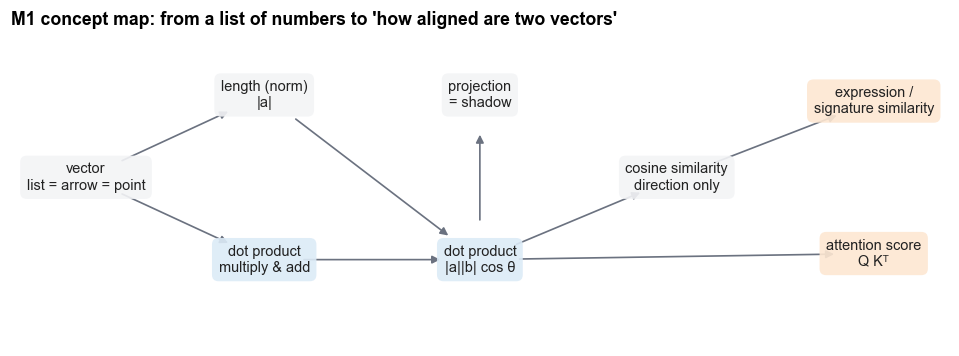

In [2]:
draw_concept_map_m1()

**그림에서 볼 것**
- 왼쪽 위에서 오른쪽으로: 숫자 목록인 벡터에서 출발해 길이와 내적을 정의하고, 내적의 두 얼굴(계산과 각도)이 만나는 곳에서 투영과 코사인 유사도가 나옵니다.
- 맨 오른쪽 두 상자가 이 노트북의 응용입니다. 발현·signature 비교(코사인)와 LLM 어텐션 점수(내적 표)입니다.

## 1. 벡터: 숫자 목록 = 화살표 = 점

**한 줄 정의**: 벡터는 숫자를 정해진 순서대로 늘어놓은 목록입니다. 숫자가 2개면 평면 위의 화살표(원점에서 그 자리까지)로도, 그 끝의 점으로도 볼 수 있습니다.

**왜 필요한가**: 표본 하나의 유전자 발현값 여러 개를 **하나의 대상**으로 다루려면 묶어야 합니다. 묶어 두면 "두 표본이 얼마나 닮았나", "어느 쪽으로 다른가"를 화살표의 길이와 방향으로 물을 수 있습니다.

**숫자로 따라가기**: 유전자 2개를 잰 표본 하나가 (3, 1) 이면, 첫째 유전자 쪽으로 3, 둘째 유전자 쪽으로 1 간 화살표입니다.

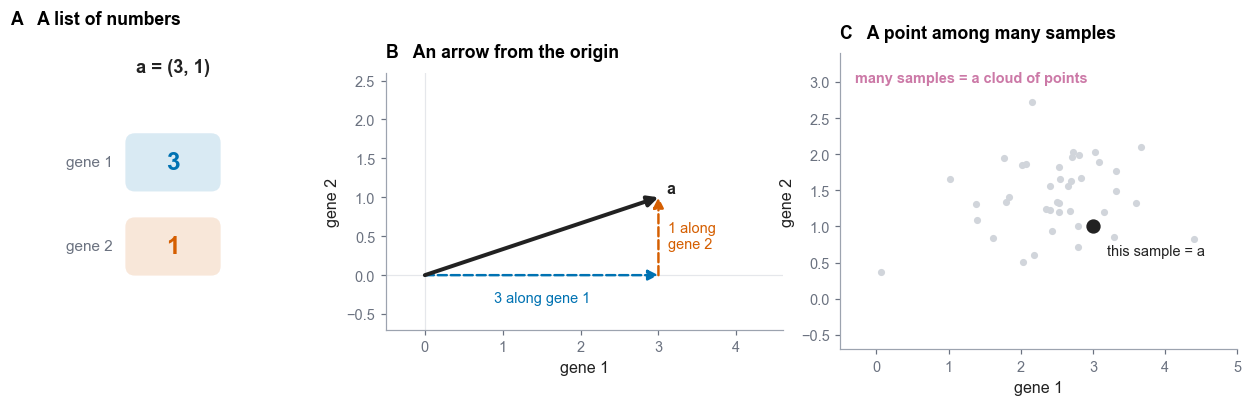

In [3]:
draw_vector_views()

**그림에서 볼 것**
- A: 같은 벡터를 숫자 두 칸으로 적은 것입니다. 칸의 순서(유전자 1, 2)가 바뀌면 다른 벡터입니다.
- B: 같은 숫자를 화살표로 그리면, 파란 점선(유전자 1 쪽 3칸)과 빨간 점선(유전자 2 쪽 1칸)을 이어 간 끝이 화살표의 끝입니다.
- C: 표본이 많으면 화살표 대신 끝점만 찍습니다. 데이터 표의 한 행 = 점 하나입니다.

> **시퀀싱 데이터에서는** 표본 하나의 96가지 염기 치환 개수(mutational catalogue)가 96칸짜리 벡터이고, 유전체를 1 kb 창으로 나눈 깊이 값도 아주 긴 벡터입니다. 칸 수가 많아 그릴 수 없을 뿐, 계산 규칙은 2칸일 때와 똑같습니다.

## 2. 길이(노름): 피타고라스

**한 줄 정의**: 벡터의 길이는 원점에서 끝점까지의 거리이고, 각 칸을 제곱해 더한 뒤 제곱근을 씌운 값입니다.

**왜 필요한가**: 내적에서 "길이 × 길이 × cos" 를 쓰려면 길이를 먼저 알아야 합니다. 두 표본 사이의 거리도 "차이 벡터의 길이"입니다.

**숫자로 따라가기**: a = (3, 4) 이면 |a| = √(3² + 4²) = √25 = 5 입니다.

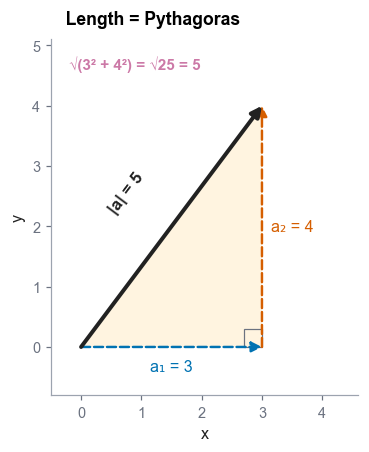

In [4]:
draw_norm()

**그림에서 볼 것**
- 파란 가로 3칸과 빨간 세로 4칸이 직각삼각형의 두 변이고, 화살표 a 가 빗변입니다. 피타고라스 정리로 빗변은 5 입니다.

**수식 풀어 읽기**

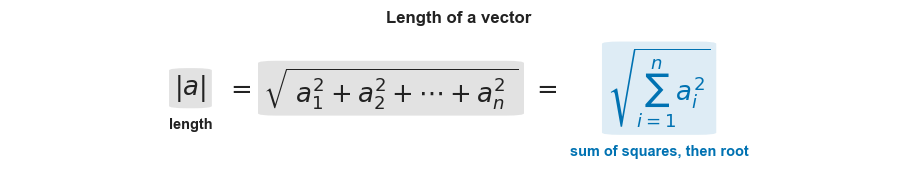

In [5]:
show_formula([(r"$|a|$", COL["ink"], "length"), (r"$=$", None, None),
              (r"$\sqrt{\;a_1^2 + a_2^2 + \cdots + a_n^2\;}$", COL["ink"], None), (r"$=$", None, None),
              (r"$\sqrt{\sum_{i=1}^{n} a_i^2}$", COL["e1"], "sum of squares, then root")],
             title="Length of a vector")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\lvert a\rvert$ | "a 의 길이(노름)" | 원점에서 끝점까지 거리 | 검은 화살표의 길이 |
| $a_i$ | "a 의 i 번째 칸" | i 번째 숫자 | 파란(1번) · 빨간(2번) 점선 |
| $\sum_{i=1}^{n}$ | "i 를 1 부터 n 까지 바꿔 가며 모두 더한다" | 칸마다 같은 계산을 하고 합침 | 두 변을 제곱해 더하기 |

**기호 사전**: $\sum$ (시그마) = "아래 적힌 번호를 하나씩 바꿔 가며 다 더한다".

칸이 3개 이상이어도 같은 식입니다. 아래에서 6칸짜리 벡터의 길이를 식과 numpy 로 계산해 같은지 확인합니다.

In [6]:
a3 = np.array([3.0, 4.0]); assert np.isclose(np.sqrt((a3 ** 2).sum()), 5.0)
v6 = np.array([1.0, 2.0, 2.0, 0.0, 4.0, 2.0])          # 1+4+4+0+16+4 = 29
by_hand = np.sqrt(sum(x ** 2 for x in v6))
assert np.isclose(by_hand, np.linalg.norm(v6)) and np.isclose(by_hand ** 2, 29)
print("6칸 벡터 길이:", round(by_hand, 3), "= √29")

6칸 벡터 길이: 5.385 = √29


**직접 바꿔 보기**: 위 셀의 `v6` 숫자를 바꿔 보세요. 칸 하나를 2배로 하면 길이가 얼마나 바뀌나요?

## 3. 내적, 계산 정의: 짝지어 곱하고 더하기

**한 줄 정의**: 두 벡터의 내적은 같은 자리 숫자끼리 곱해 모두 더한 값입니다. 결과는 벡터가 아니라 숫자 하나입니다.

**왜 필요한가**: 이 단순한 계산이 "두 벡터가 같은 방향을 보는 정도"를 잰다는 것이 이 노트북의 핵심입니다(4절에서 이유를 봅니다). 행렬 곱(M2)도 이 계산을 표처럼 반복한 것입니다.

**숫자로 따라가기**: a = (3, 1), b = (2, 2) 이면 a · b = 3×2 + 1×2 = 8 입니다.

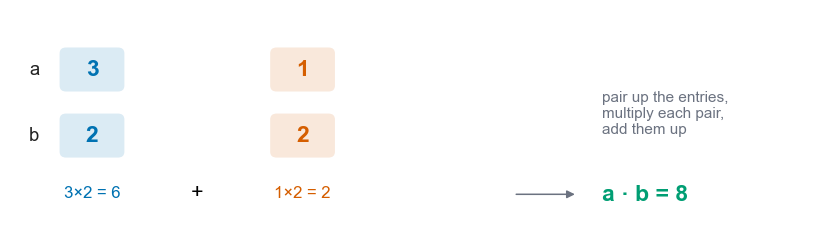

In [7]:
draw_dot_algebra()

**그림에서 볼 것**
- 위아래로 같은 자리(파랑끼리, 빨강끼리)만 짝을 짓습니다. 자리가 다른 숫자끼리는 곱하지 않습니다.
- 짝마다 곱한 값(6 과 2)을 더한 8 이 내적입니다.

**수식 풀어 읽기**

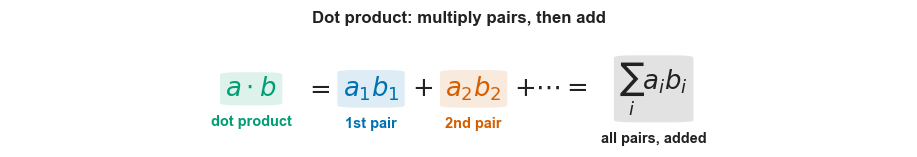

In [8]:
show_formula([(r"$a \cdot b$", COL["result"], "dot product"), (r"$=$", None, None),
              (r"$a_1 b_1$", COL["e1"], "1st pair"), (r"$+$", None, None),
              (r"$a_2 b_2$", COL["e2"], "2nd pair"), (r"$+ \cdots =$", None, None),
              (r"$\sum_{i} a_i b_i$", COL["ink"], "all pairs, added")],
             title="Dot product: multiply pairs, then add")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $a \cdot b$ | "a 내적 b" | 짝지어 곱한 값의 합(숫자 하나) | 초록 8 |
| $a_i b_i$ | "a 의 i 번째 곱하기 b 의 i 번째" | i 번째 짝의 곱 | 3×2 = 6, 1×2 = 2 |

같은 식을 numpy 의 `a @ b` 와 비교합니다.

In [9]:
a = np.array([3.0, 1.0]); b = np.array([2.0, 2.0])
by_hand = sum(x * y for x, y in zip(a, b))
assert by_hand == 8 and np.isclose(by_hand, a @ b)
print("a · b =", by_hand)

a · b = 8.0


## 4. 내적, 각도 정의: 왜 "곱해서 더하기"가 각도를 아나

**한 줄 정의**: 내적은 두 길이와 사잇각의 cos 을 곱한 값, $|a||b|\cos\theta$ 와 같습니다.

**왜 필요한가**: 이 등식 덕분에 각도를 재지 않고도 곱셈과 덧셈만으로 "얼마나 같은 방향인가"를 알 수 있습니다. 컴퓨터는 각도기가 없어도 됩니다.

**숫자로 따라가기**: a = (3, 1), b = (2, 2) 에서 |a| = √10 ≈ 3.162, |b| = √8 ≈ 2.828, 사잇각은 약 26.57° 이고 cos 은 약 0.894 입니다. 곱하면 3.162 × 2.828 × 0.894 ≈ 8.0 으로, 3절의 8 과 같습니다.

왜 같은지는 삼각형 하나로 보입니다. a, b 와 그 차이 a − b 가 삼각형을 이룹니다.

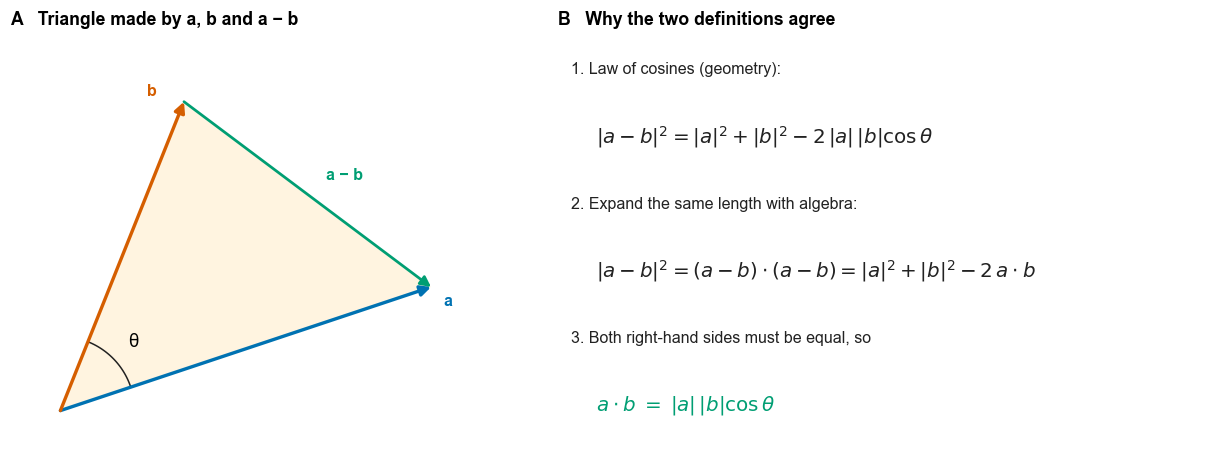

In [10]:
draw_law_of_cosines()

**그림에서 볼 것**
- A: 파란 a, 빨간 b, 초록 a − b 가 삼각형의 세 변입니다. 사잇각이 θ 입니다.
- B: 초록 변의 길이를 두 가지로 셉니다. 1번은 기하학(코사인 법칙), 2번은 3절의 "짝지어 곱하기"로 $(a-b)\cdot(a-b)$ 를 펼친 것입니다. 둘 다 같은 길이이므로 남는 항끼리 같아야 하고, 그것이 3번 식입니다.

2번 줄을 펼치는 과정을 한 칸씩 쓰면 이렇습니다(이 노트북에서 유도).

$(a-b)\cdot(a-b) = a\cdot a - a\cdot b - b\cdot a + b\cdot b = |a|^2 - 2\,a\cdot b + |b|^2$

여기서 $a\cdot a = |a|^2$ 는 2절의 길이 식과 같은 말입니다(자기 자신과 짝지어 곱해 더하면 제곱의 합).

**수식 풀어 읽기**

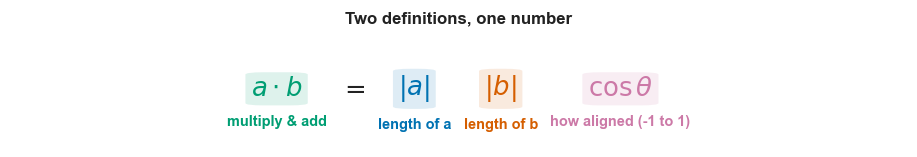

In [11]:
show_formula([(r"$a \cdot b$", COL["result"], "multiply & add"), (r"$=$", None, None),
              (r"$|a|$", COL["e1"], "length of a"), (r"$|b|$", COL["e2"], "length of b"),
              (r"$\cos\theta$", COL["highlight"], "how aligned (-1 to 1)")],
             title="Two definitions, one number")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\theta$ | "세타" | 두 화살표 사이 각도 | A 의 호 |
| $\cos\theta$ | "코사인 세타" | 같은 방향 1, 직각 0, 반대 −1 | 5절 그림 B 의 곡선 |

무작위 벡터 1만 쌍으로 두 정의가 늘 같은지 확인합니다(이 노트북의 시뮬레이션).

In [12]:
rng = np.random.default_rng(0)
X = rng.normal(size=(10000, 5)); Y = rng.normal(size=(10000, 5))
algebra = (X * Y).sum(axis=1)
# 각도는 내적 없이 코사인 법칙으로만 구한다: cos θ = (|a|² + |b|² − |a−b|²) / (2|a||b|)
na, nb, nd = np.linalg.norm(X, axis=1), np.linalg.norm(Y, axis=1), np.linalg.norm(X - Y, axis=1)
cos_theta = (na ** 2 + nb ** 2 - nd ** 2) / (2 * na * nb)
geometry = na * nb * cos_theta
assert np.allclose(algebra, geometry)
print("1만 쌍 모두 같음. 가장 큰 차이:", f"{np.abs(algebra - geometry).max():.1e}")

1만 쌍 모두 같음. 가장 큰 차이: 1.2e-14


**직접 바꿔 보기**: 위 셀에서 칸 수 `5` 를 100 으로 바꿔도 등식이 그대로 성립하는지 보세요. 그림으로는 못 그려도 식은 그대로입니다.

## 5. 내적의 부호: 같은 쪽이면 +, 직각이면 0, 반대쪽이면 −

**한 줄 정의**: 길이가 같다면 내적은 각도만으로 정해지고, 부호가 "같은 쪽인가 반대쪽인가"를 알려 줍니다.

**왜 필요한가**: 내적 0 은 "서로 전혀 상관없는 방향(직교)"이라는 뜻이라, 회귀(M3)와 PCA(M4)에서 계속 나옵니다.

**숫자로 따라가기**: a = (2, 0), 길이 1.6 인 b 를 20° 에서 170° 까지 돌리면 내적은 2 × 1.6 × cos θ 로 +3.0 에서 −3.2 까지 바뀝니다.

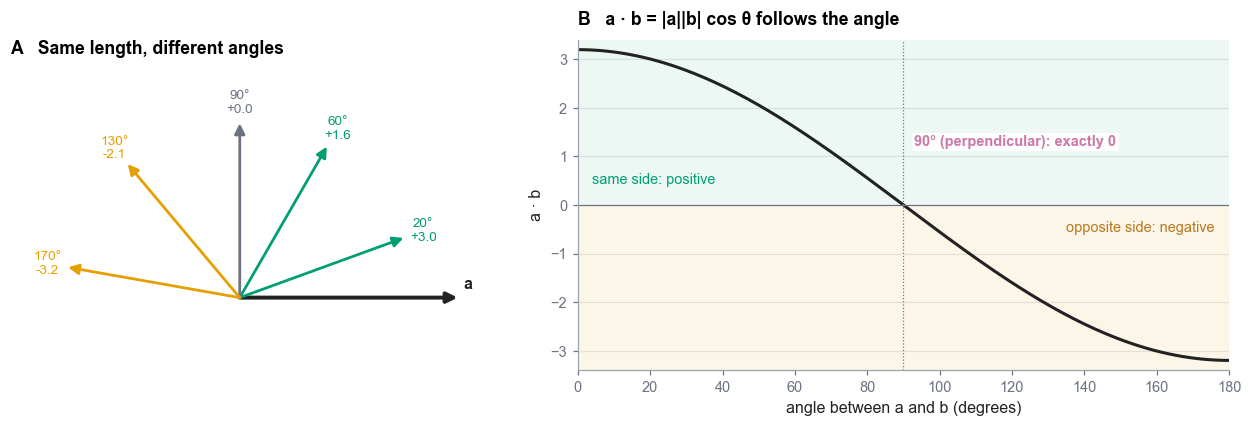

In [13]:
draw_dot_vs_angle()

**그림에서 볼 것**
- A: 초록 화살표(a 와 같은 쪽)는 내적이 +, 주황 화살표(반대쪽)는 −, 90° 의 회색은 0 입니다. 숫자가 각 화살표의 내적입니다.
- B: 같은 내적을 각도에 따라 그리면 cos 곡선입니다. 90° 에서 정확히 0 을 지납니다.

## 6. 투영: a 가 b 위에 드리운 그림자

**한 줄 정의**: a 를 b 의 직선 위로 수직으로 떨어뜨린 그림자가 a 의 b 위 투영이고, 그림자 길이는 $a\cdot b / |b|$ 입니다.

**왜 필요한가**: "a 중에 b 방향 몫이 얼마인가"를 묻는 계산입니다. 최소제곱(M3)은 이 그림자를 평면으로 넓힌 것이고, PCA(M4)는 점들을 주성분 방향으로 투영합니다.

**숫자로 따라가기**: a = (3, 1), b = (1, 1) 이면 a·b = 4, b·b = 2 라 그림자는 (4/2) × b = 2b = (2, 2) 입니다. 그림자 길이는 a·b / |b| = 4 / 1.41 = 2.83 입니다.

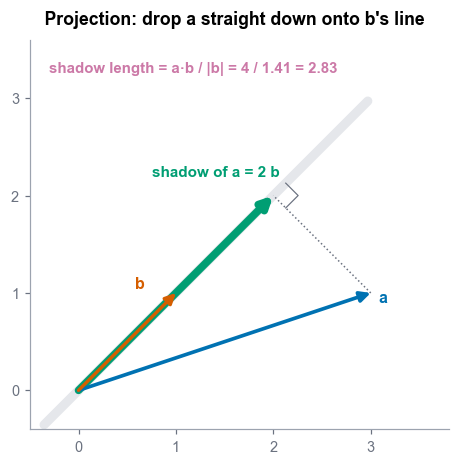

In [14]:
p = draw_projection()

**그림에서 볼 것**
- 파란 a 끝에서 회색 점선을 b 의 직선(옅은 띠)에 수직으로 내리면, 닿은 곳까지가 초록 그림자입니다. 그림자는 빨간 b 를 두 번 이은 길이(2b)입니다.
- 점선과 띠가 만나는 곳의 작은 꺾쇠가 직각 표시입니다. 이 직각이 "가장 가까운 점"이라는 뜻이고, M3 의 최소제곱이 바로 이것입니다.

**수식 풀어 읽기**

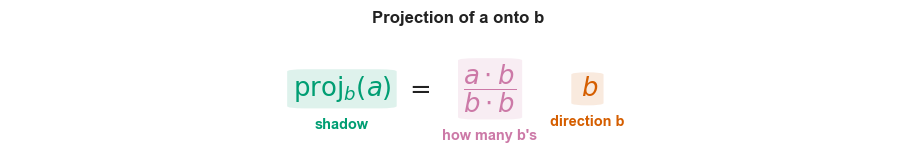

In [15]:
show_formula([(r"$\mathrm{proj}_b(a)$", COL["result"], "shadow"), (r"$=$", None, None),
              (r"$\dfrac{a\cdot b}{b\cdot b}$", COL["highlight"], "how many b's"), (r"$\,b$", COL["e2"], "direction b")],
             title="Projection of a onto b")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\mathrm{proj}_b(a)$ | "a 의 b 위 투영" | b 의 직선 위 그림자(벡터) | 초록 화살표 |
| $\dfrac{a\cdot b}{b\cdot b}$ | "a 내적 b 나누기 b 내적 b" | 그림자가 b 몇 개만큼인가 | 이 예에서는 4/2 = 2 |

그림자와 나머지(a − 그림자)가 정말 직각인지, 즉 내적이 0 인지 확인합니다.

In [16]:
b1 = np.array([1.0, 1.0])
assert np.allclose(p, [2, 2]) and np.isclose((a - p) @ b1, 0)
print("그림자:", p, "  (a − 그림자)·b =", (a - p) @ b1)

그림자: [2. 2.]   (a − 그림자)·b = 0.0


**직접 바꿔 보기**: `draw_projection(a=(1, 3))` 처럼 a 를 바꿔 그림자 길이가 어떻게 바뀌는지 보세요. a 를 b 와 직각인 (2, −2) 로 하면 그림자는 어떻게 될까요?

In [17]:
# draw_projection(a=(1, 3))

## 7. 코사인 유사도: 길이는 빼고 방향만 비교하기

**한 줄 정의**: 내적을 두 길이로 나눈 값 $\cos\theta = a\cdot b / (|a||b|)$ 이고, −1 에서 1 사이입니다.

**왜 필요한가**: 시퀀싱을 두 배 깊게 하면 모든 유전자의 count 가 대략 두 배가 됩니다. 이때 내적이나 거리는 크게 바뀌지만, 발현 **패턴**은 그대로입니다. 패턴만 비교하려면 길이를 나눠 없애야 합니다.

**숫자로 따라가기**: 표본 B = 2 × 표본 A 이면 cos(A, B) = 1 입니다. 패턴이 다른 표본 C 와는 1 보다 작습니다.

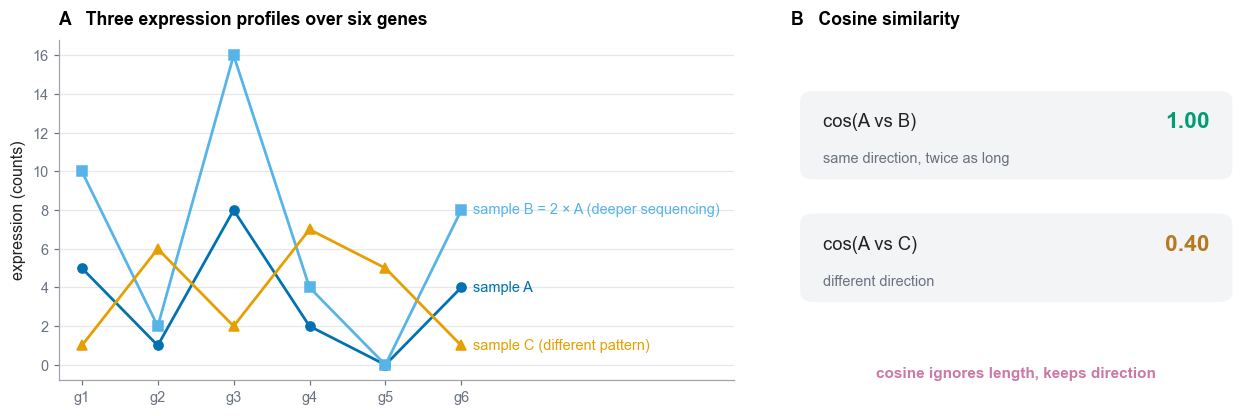

In [18]:
draw_cosine_profiles()

**그림에서 볼 것**
- A: 하늘색 B 는 파란 A 를 모든 유전자에서 2 배 한 것이라 모양이 같고 높이만 다릅니다. 주황 C 는 모양이 다릅니다.
- B: A 와 B 의 코사인은 1.00 으로 "완전히 같은 방향"이고, A 와 C 는 그보다 작습니다(진한 주황 숫자). 길이(깊이) 차이는 코사인에 들어가지 않습니다.

**수식 풀어 읽기**

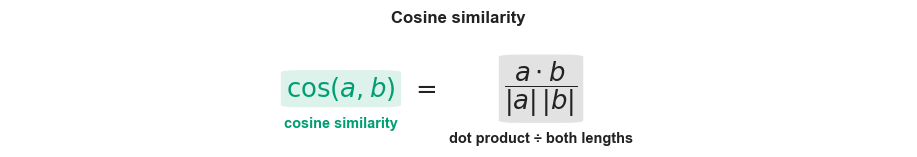

In [19]:
show_formula([(r"$\cos(a,b)$", COL["result"], "cosine similarity"), (r"$=$", None, None),
              (r"$\dfrac{a\cdot b}{|a|\,|b|}$", COL["ink"], "dot product ÷ both lengths")],
             title="Cosine similarity")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\cos(a, b)$ | "a 와 b 의 코사인 유사도" | 방향이 같은 정도(1 같음, 0 무관, −1 반대) | B 의 초록·진한 주황 숫자 |

덤으로, **피어슨 상관계수는 평균을 뺀 두 벡터의 코사인**과 같습니다. 아래에서 확인합니다(이 노트북에서 계산).

In [20]:
A_ = np.array([5, 1, 8, 2, 0, 4.0]); B_ = 2 * A_; C_ = np.array([1, 6, 2, 7, 5, 1.0])
cosf = lambda x, y: x @ y / np.linalg.norm(x) / np.linalg.norm(y)
assert np.isclose(cosf(A_, B_), 1.0)
pearson = np.corrcoef(A_, C_)[0, 1]
assert np.isclose(pearson, cosf(A_ - A_.mean(), C_ - C_.mean()))
print(f"cos(A, C) = {cosf(A_, C_):.3f},  pearson(A, C) = {pearson:.3f} = cos(평균 뺀 A, 평균 뺀 C)")

cos(A, C) = 0.398,  pearson(A, C) = -0.724 = cos(평균 뺀 A, 평균 뺀 C)


> **시퀀싱 데이터에서는** mutational signature 를 비교할 때 코사인 유사도를 씁니다. Alexandrov 등(2013)은 뽑아낸 signature 가 시뮬레이션에 쓴 signature 와 얼마나 같은지를 코사인 유사도로 쟀습니다 [5]. 96칸 비율 벡터의 "모양"만 비교하는 것이라, 변이 개수가 많은 표본과 적은 표본도 같은 기준으로 비교됩니다.

## 8. 응용: LLM 어텐션 점수는 내적의 표

**한 줄 정의**: 어텐션 점수 표 $QK^\top$ 의 칸 하나는 질문(query) 벡터 하나와 열쇠(key) 벡터 하나의 내적입니다 [4].

**왜 필요한가**: "이 토큰이 어느 토큰을 볼지"를 정하는 점수가 내적입니다. 4절에서 본 대로 내적 = $|q||k|\cos\theta$ 라, 점수에는 **방향이 같은 정도와 두 벡터의 길이가 함께** 들어 있습니다. 부호만 보면 사잇각이 90° 보다 작은지(+) 큰지(−)를 알 수 있습니다. Vaswani 등은 내적을 $\sqrt{d_k}$ 로 나눈 뒤 softmax 를 씌웁니다 [4].

**용어 사전**: softmax = 점수 묶음을 "0 과 1 사이, 합이 1" 인 비율로 바꾸는 함수입니다(각 점수에 지수를 취한 뒤 그 합으로 나눔). 자세한 것은 [CS329Z A1 노트북](../cs329z-llms-for-builders/lab01_sampling.ipynb)에 있습니다.

**숫자로 따라가기**: 토큰 4개, 벡터 길이 3 짜리 장난감에서 칸 하나를 손으로 계산합니다. 실제 GPT-2 에서 같은 계산을 하는 것은 [CS329Z A2 노트북](../cs329z-llms-for-builders/lab02_attention.ipynb)에 있습니다.

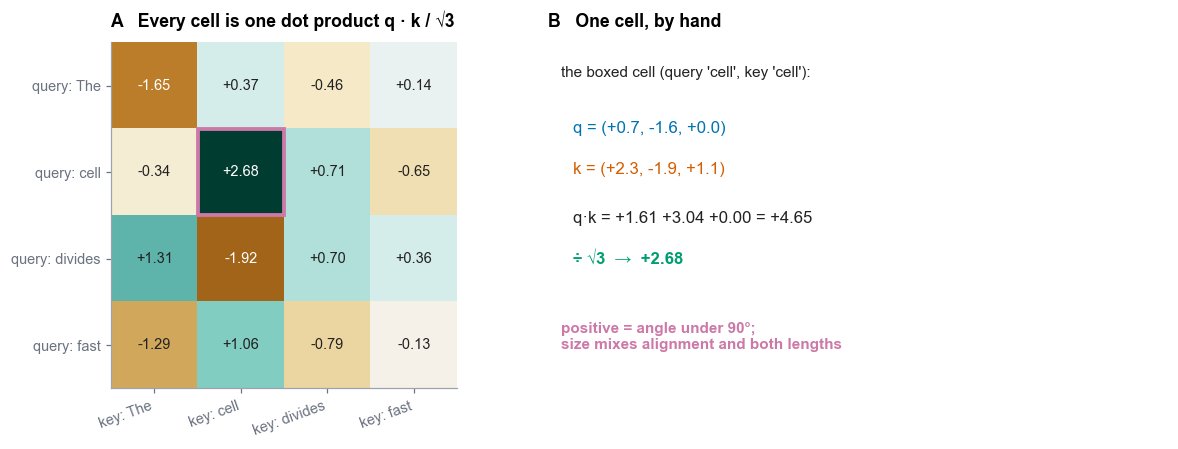

In [21]:
Q, K, S = draw_attention_scores()

**그림에서 볼 것**
- A: 칸마다 "줄의 query · 열의 key ÷ √3" 입니다. 초록 칸(+)은 두 벡터의 사잇각이 90° 보다 작고, 갈색 칸(−)은 90° 보다 큽니다. 칸의 크기는 방향과 두 길이를 함께 반영합니다.
- B: 자주색 네모 칸(가장 큰 양수 칸) 하나를 손으로 계산했습니다. 세 짝을 곱해 더하고 √3 으로 나눈 값이 A 의 칸 숫자와 같습니다.

**수식 풀어 읽기**

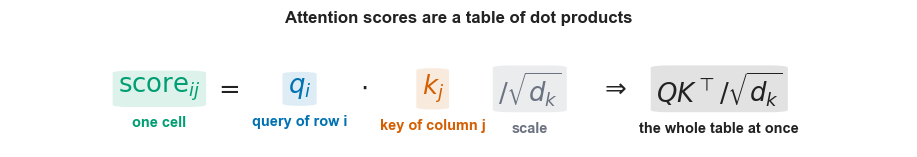

In [22]:
show_formula([(r"$\mathrm{score}_{ij}$", COL["result"], "one cell"), (r"$=$", None, None),
              (r"$q_i$", COL["e1"], "query of row i"), (r"$\cdot$", None, None), (r"$k_j$", COL["e2"], "key of column j"),
              (r"$/\sqrt{d_k}$", COL["muted"], "scale"), (r"$\quad\Rightarrow\quad$", None, None),
              (r"$QK^\top/\sqrt{d_k}$", COL["ink"], "the whole table at once")],
             title="Attention scores are a table of dot products")

표 전체를 `Q @ K.T` 한 번으로 만든 것과 칸마다 내적한 것이 같은지 확인합니다. 행렬 곱이 "내적의 표"라는 이 관점은 M2 의 첫 번째 눈입니다.

In [23]:
by_cells = np.array([[Q[i] @ K[j] for j in range(4)] for i in range(4)]) / np.sqrt(3)
assert np.allclose(by_cells, S)
print("Q @ K.T / √3 == 칸마다 내적:", np.allclose(by_cells, S))

Q @ K.T / √3 == 칸마다 내적: True


## 연습 문제

1. a = (1, 2, 3), b = (4, −5, 6) 의 내적은?
2. a = (1, 0), b = (1, 1) 의 사잇각은? (내적과 길이만으로 구하세요.)
3. a = (4, 2) 를 b = (1, 0) 위로 투영한 그림자는?
4. 표본 x 의 모든 count 를 10 배 하면 x 와 y 의 코사인 유사도는 어떻게 되나요?

<details><summary>정답 보기</summary>

1. 1×4 + 2×(−5) + 3×6 = 4 − 10 + 18 = 12.
2. a·b = 1, |a| = 1, |b| = √2 → cos θ = 1/√2 → θ = 45°.
3. (a·b / b·b) b = (4/1)(1, 0) = (4, 0).
4. 그대로입니다. 분자의 내적도 10 배, 분모의 |x| 도 10 배라 나누면 지워집니다.

</details>

In [24]:
assert np.array([1, 2, 3]) @ np.array([4, -5, 6]) == 12
assert np.isclose(np.degrees(np.arccos(1 / np.sqrt(2))), 45)
assert np.allclose((np.array([4, 2]) @ np.array([1, 0])) / 1 * np.array([1, 0]), [4, 0])
x_, y_ = rng.random(8), rng.random(8)
assert np.isclose(cosf(10 * x_, y_), cosf(x_, y_))

## 정리

- 벡터는 숫자 목록이고, 화살표이며, 점입니다. 칸이 많아도 규칙은 같습니다.
- 내적은 "짝지어 곱해 더하기"이고, 코사인 법칙으로 보면 $|a||b|\cos\theta$ 와 같습니다. 그래서 곱셈과 덧셈만으로 방향이 같은 정도를 잽니다.
- 투영은 내적으로 구한 그림자이고, 그림자와 나머지는 직각입니다(M3 최소제곱의 출발점).
- 코사인 유사도는 길이를 나눠 없앤 내적이라, 시퀀싱 깊이가 다른 표본이나 변이 수가 다른 catalogue 의 **모양**을 비교합니다.
- 어텐션 점수 표는 내적을 칸마다 늘어놓은 것이고, 이것이 다음 노트북(M2)의 행렬 곱입니다.

## 출처

1. MIT OpenCourseWare, 18.06 Linear Algebra (Gilbert Strang), Spring 2010, Video Lectures 목록. https://ocw.mit.edu/courses/18-06-linear-algebra-spring-2010/video_galleries/video-lectures/ — 머리의 "같이 볼 강의" 회차와 제목.
2. 3Blue1Brown (Grant Sanderson), "Essence of linear algebra" 재생목록(16장). https://www.youtube.com/playlist?list=PLZHQObOWTQDPD3MizzM2xVFitgF8hE_ab — Chapter 1 "Vectors"(fNk_zzaMoSs), Chapter 9 "Dot products and duality"(LyGKycYT2v0). 장 번호와 제목만 확인했고 영상 내용을 인용하지는 않았습니다.
3. (출처 없음) 4절의 코사인 법칙 유도와 두 정의가 같다는 확인, 7절의 피어슨 상관 = 평균 뺀 코사인은 **이 노트북에서 직접 유도·계산**한 것입니다.
4. Vaswani A, et al. (2017). Attention Is All You Need. arXiv:1706.03762. https://arxiv.org/abs/1706.03762 — §3.2.1 "Scaled Dot-Product Attention", 식 (1) $\mathrm{Attention}(Q,K,V)=\mathrm{softmax}(QK^\top/\sqrt{d_k})V$ 와 "We compute the dot products of the query with all keys, divide each by √dk" (8절).
5. Alexandrov LB, Nik-Zainal S, Wedge DC, Campbell PJ, Stratton MR (2013). Deciphering signatures of mutational processes operative in human cancer. *Cell Reports* 3(1):246–259. doi:10.1016/j.celrep.2012.12.008, PMID 23318258. — Figure 2 설명 "Signature recognition, measured using cosine similarity" (7절 시퀀싱 상자).